## Data Preprocessing

### Import Libraries

In [98]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt # Visualization
import seaborn as sns
from sklearn.model_selection import train_test_split # Preprocessing
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
import warnings
import time
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc
warnings.filterwarnings("ignore")

In [99]:
df = pd.read_csv('Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv')
df.head()

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,22,1266342,41,44,2664,6954,456,0,64.975610,109.864573,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,22,1319353,41,44,2664,6954,456,0,64.975610,109.864573,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,22,160,1,1,0,0,0,0,0.000000,0.000000,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,22,1303488,41,42,2728,6634,456,0,66.536585,110.129945,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,35396,77,1,2,0,0,0,0,0.000000,0.000000,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [100]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 286467 entries, 0 to 286466
Data columns (total 79 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0    Destination Port             286467 non-null  int64  
 1    Flow Duration                286467 non-null  int64  
 2    Total Fwd Packets            286467 non-null  int64  
 3    Total Backward Packets       286467 non-null  int64  
 4   Total Length of Fwd Packets   286467 non-null  int64  
 5    Total Length of Bwd Packets  286467 non-null  int64  
 6    Fwd Packet Length Max        286467 non-null  int64  
 7    Fwd Packet Length Min        286467 non-null  int64  
 8    Fwd Packet Length Mean       286467 non-null  float64
 9    Fwd Packet Length Std        286467 non-null  float64
 10  Bwd Packet Length Max         286467 non-null  int64  
 11   Bwd Packet Length Min        286467 non-null  int64  
 12   Bwd Packet Length Mean       286467 non-nul

In [101]:
df.columns = df.columns.str.strip()
df[['Fwd Header Length', 'Fwd Header Length.1']].head(10)

,Fwd Header Length,Fwd Header Length.1
0,1328,1328
1,1328,1328
2,32,32
3,1328,1328
4,32,32
5,32,32
6,1328,1328
7,32,32
8,32,32
9,32,32


In [102]:
df = df.drop(columns=["Fwd Header Length.1"], errors="ignore")
df.shape

(286467, 78)

In [103]:
df.isna().sum().sort_values(ascending=False)

Flow Bytes/s            15
Destination Port         0
Bwd Avg Packets/Bulk     0
Fwd Avg Bulk Rate        0
Fwd Avg Packets/Bulk     0
                        ..
Bwd IAT Mean             0
Bwd IAT Total            0
Fwd IAT Min              0
Fwd IAT Max              0
Label                    0
Length: 78, dtype: int64

In [104]:
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)

np.isinf(df.select_dtypes(include=[np.number])).sum().sum()
df.isna().sum().sum()

np.int64(0)

In [105]:
df['Label'].value_counts()

Label
PortScan    158804
BENIGN      127292
Name: count, dtype: int64

In [106]:
df['Label'] = df['Label'].map({
    'BENIGN': 0,
    'PortScan': 1
})

In [107]:
df['Label'].value_counts()

Label
1    158804
0    127292
Name: count, dtype: int64

In [108]:
X = df.drop(columns=['Label'])
y = df['Label']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,      # 20% test
    random_state=42,    # reproducibility
    stratify=y          # preserve class distribution
)


In [109]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape


((228876, 77), (57220, 77), (228876,), (57220,))

In [110]:
y_train.value_counts()
y_train.value_counts(normalize=True)


Label
1    0.555073
0    0.444927
Name: proportion, dtype: float64

In [111]:
smote = SMOTE(random_state=42)

X_train_res, y_train_res = smote.fit_resample(X_train, y_train)



In [112]:

y_train_res.value_counts()
y_train_res.value_counts(normalize=True)

Label
1    0.5
0    0.5
Name: proportion, dtype: float64

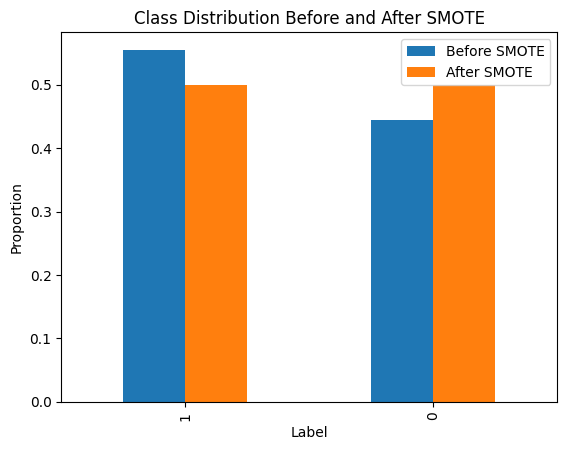

In [113]:
dist_smote = pd.DataFrame({
    'Before SMOTE': y_train.value_counts(normalize=True),
    'After SMOTE': y_train_res.value_counts(normalize=True)
})

dist_smote.plot(kind='bar')
plt.ylabel('Proportion')
plt.title('Class Distribution Before and After SMOTE')
plt.show()


In [114]:
scaler = StandardScaler()

# Fit on SMOTE-balanced training data
X_train_res_scaled = scaler.fit_transform(X_train_res)

# Transform test data using same scaler
X_test_scaled = scaler.transform(X_test)

In [115]:
X_train_res_scaled = pd.DataFrame(
    X_train_res_scaled,
    columns=X_train.columns,
    index=X_train_res.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_train.columns,
    index=X_test.index
)


In [116]:
X_test_scaled.head()


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
100178,-0.131742,-0.260799,-0.132923,-0.096557,-0.135656,-0.056712,-0.262704,-0.368647,-0.308537,-0.225799,...,-0.123533,-0.596348,-0.074604,-0.092232,-0.110502,-0.052776,-0.196258,-0.053259,-0.197142,-0.190668
252334,-0.507118,-0.260791,-0.084963,-0.062260,-0.055231,-0.051529,-0.038281,2.534345,0.626997,-0.225799,...,-0.059920,-1.103348,-0.074604,-0.092232,-0.110502,-0.052776,-0.196258,-0.053259,-0.197142,-0.190668
202683,-0.475371,-0.260799,-0.132923,-0.096557,-0.136714,-0.056712,-0.268689,-0.446060,-0.333485,-0.225799,...,-0.123533,1.431648,-0.074604,-0.092232,-0.110502,-0.052776,-0.196258,-0.053259,-0.197142,-0.190668
180974,-0.414316,-0.260798,-0.132923,-0.096557,-0.136714,-0.056712,-0.268689,-0.446060,-0.333485,-0.225799,...,-0.123533,1.431648,-0.074604,-0.092232,-0.110502,-0.052776,-0.196258,-0.053259,-0.197142,-0.190668
263875,-0.505386,3.049200,0.346680,0.246414,0.091863,-0.022796,1.023988,-0.446060,0.156395,0.855474,...,-0.059920,0.417650,-0.013974,-0.024823,-0.017712,-0.003827,0.915948,-0.020776,0.889846,0.925967


In [117]:
X_test_scaled.describe().round(3)

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
count,57220.000,57220.000,57220.000,57220.000,57220.000,57220.000,57220.000,57220.000,57220.000,57220.000,...,57220.000,57220.000,57220.000,57220.000,57220.000,57220.000,57220.000,57220.000,57220.000,57220.000
mean,-0.000,-0.029,-0.014,-0.008,-0.013,-0.004,-0.019,-0.047,-0.026,-0.014,...,-0.014,0.047,-0.013,-0.005,-0.012,-0.012,-0.023,-0.007,-0.024,-0.023
std,0.977,0.946,0.939,1.093,1.007,1.044,1.045,0.850,1.023,1.028,...,0.981,1.017,0.584,0.860,0.830,0.536,0.945,0.894,0.945,0.945
min,-0.511,-0.261,-0.133,-0.131,-0.137,-0.057,-0.269,-0.446,-0.333,-0.226,...,-0.124,-3.638,-0.075,-0.092,-0.111,-0.053,-0.196,-0.053,-0.197,-0.191
25%,-0.505,-0.261,-0.133,-0.097,-0.137,-0.057,-0.269,-0.446,-0.333,-0.226,...,-0.124,-1.103,-0.075,-0.092,-0.111,-0.053,-0.196,-0.053,-0.197,-0.191
50%,-0.439,-0.261,-0.133,-0.097,-0.136,-0.057,-0.263,-0.369,-0.309,-0.226,...,-0.124,-0.596,-0.075,-0.092,-0.111,-0.053,-0.196,-0.053,-0.197,-0.191
75%,-0.075,-0.260,-0.085,-0.062,-0.104,-0.055,-0.158,-0.214,0.091,-0.226,...,-0.060,1.432,-0.075,-0.092,-0.111,-0.053,-0.196,-0.053,-0.197,-0.191
max,3.683,4.929,93.006,124.539,88.349,114.872,41.411,56.530,42.239,27.022,...,123.414,1.939,40.826,45.505,43.422,44.668,12.889,47.109,12.591,13.076



===== STANDALONE RF TEST PERFORMANCE =====

Accuracy:
0.9999126179657463

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     25459
           1       1.00      1.00      1.00     31761

    accuracy                           1.00     57220
   macro avg       1.00      1.00      1.00     57220
weighted avg       1.00      1.00      1.00     57220


Confusion Matrix:
[[25458     1]
 [    4 31757]]


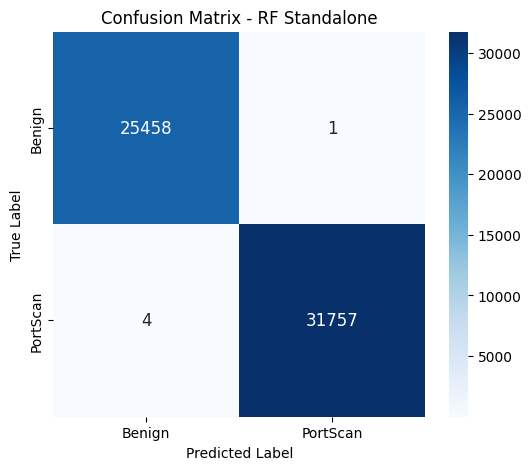


RF Standalone AUC Score: 1.0


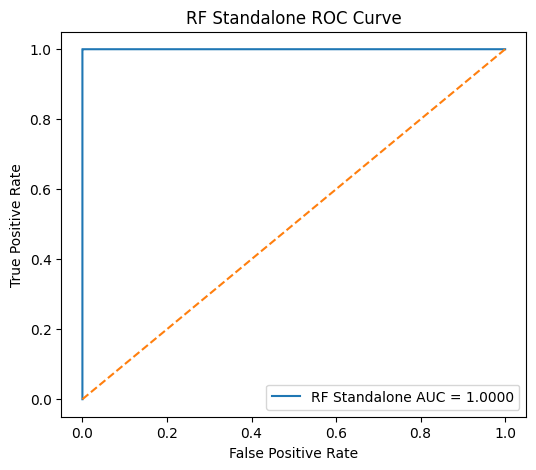


===== STANDALONE RF TRAINING PERFORMANCE =====

Training Accuracy:
1.0

Training Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    127043
           1       1.00      1.00      1.00    127043

    accuracy                           1.00    254086
   macro avg       1.00      1.00      1.00    254086
weighted avg       1.00      1.00      1.00    254086


Training Confusion Matrix:
[[127043      0]
 [     0 127043]]

RF Standalone Time: 4.45 seconds

===== STANDALONE XGBOOST TEST PERFORMANCE =====

Accuracy:
0.9999650471862985

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     25459
           1       1.00      1.00      1.00     31761

    accuracy                           1.00     57220
   macro avg       1.00      1.00      1.00     57220
weighted avg       1.00      1.00      1.00     57220


Confusion Matrix:
[[25458     1]
 [    1

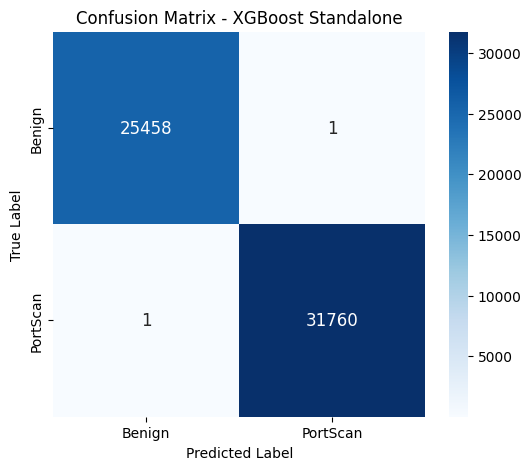


XGBoost Standalone AUC Score: 1.0


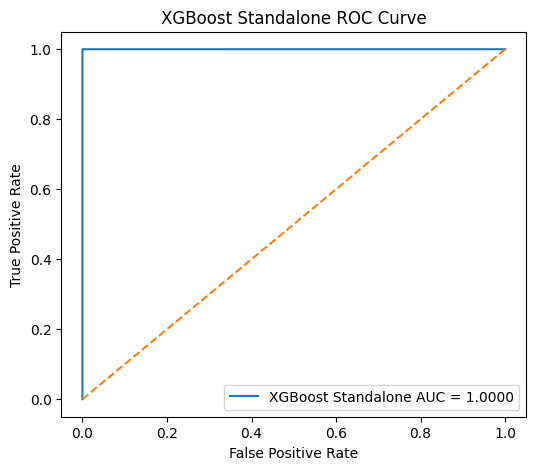


===== STANDALONE XGBOOST TRAINING PERFORMANCE =====

Training Accuracy:
1.0

Training Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    127043
           1       1.00      1.00      1.00    127043

    accuracy                           1.00    254086
   macro avg       1.00      1.00      1.00    254086
weighted avg       1.00      1.00      1.00    254086


Training Confusion Matrix:
[[127043      0]
 [     0 127043]]

XGBoost Standalone Time: 1.18 seconds


In [118]:
# =========================================
# STANDALONE CLASSIFIERS BASELINE
# ALL 77 FEATURES - NO OPTIMIZATION
# =========================================
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# =========================================
# RF STANDALONE
# =========================================
start_rf_standalone = time.time()

rf_standalone = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
rf_standalone.fit(X_train_res_scaled, y_train_res)
rf_standalone_pred = rf_standalone.predict(X_test_scaled)

end_rf_standalone = time.time()
rf_standalone_time = end_rf_standalone - start_rf_standalone

# TEST PERFORMANCE
print("\n===== STANDALONE RF TEST PERFORMANCE =====")
print("\nAccuracy:")
print(accuracy_score(y_test, rf_standalone_pred))
print("\nClassification Report:")
print(classification_report(y_test, rf_standalone_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_standalone_pred))

# CONFUSION MATRIX VISUALIZATION
cm_rf = confusion_matrix(y_test, rf_standalone_pred)
plt.figure(figsize=(6,5))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Benign', 'PortScan'],
    yticklabels=['Benign', 'PortScan'],
    annot_kws={"size":12}
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - RF Standalone")
plt.savefig("confusion_matrix_rf_standalone.png", dpi=300, bbox_inches='tight')
plt.show()

# ROC CURVE
y_probs_rf_standalone = rf_standalone.predict_proba(X_test_scaled)[:, 1]
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_probs_rf_standalone)
auc_rf = auc(fpr_rf, tpr_rf)
print("\nRF Standalone AUC Score:", round(auc_rf, 4))

plt.figure(figsize=(6,5))
plt.plot(fpr_rf, tpr_rf, label=f"RF Standalone AUC = {auc_rf:.4f}")
plt.plot([0,1], [0,1], linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("RF Standalone ROC Curve")
plt.legend()
plt.show()

# TRAINING PERFORMANCE
y_train_pred_rf_standalone = rf_standalone.predict(X_train_res_scaled)
print("\n===== STANDALONE RF TRAINING PERFORMANCE =====")
print("\nTraining Accuracy:")
print(accuracy_score(y_train_res, y_train_pred_rf_standalone))
print("\nTraining Classification Report:")
print(classification_report(y_train_res, y_train_pred_rf_standalone))
print("\nTraining Confusion Matrix:")
print(confusion_matrix(y_train_res, y_train_pred_rf_standalone))

print("\nRF Standalone Time:", round(rf_standalone_time, 2), "seconds")

# =========================================
# XGBOOST STANDALONE
# =========================================
start_xgb_standalone = time.time()

xgb_standalone = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)
xgb_standalone.fit(X_train_res_scaled, y_train_res)
xgb_standalone_pred = xgb_standalone.predict(X_test_scaled)

end_xgb_standalone = time.time()
xgb_standalone_time = end_xgb_standalone - start_xgb_standalone

# TEST PERFORMANCE
print("\n===== STANDALONE XGBOOST TEST PERFORMANCE =====")
print("\nAccuracy:")
print(accuracy_score(y_test, xgb_standalone_pred))
print("\nClassification Report:")
print(classification_report(y_test, xgb_standalone_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, xgb_standalone_pred))

# CONFUSION MATRIX VISUALIZATION
cm_xgb = confusion_matrix(y_test, xgb_standalone_pred)
plt.figure(figsize=(6,5))
sns.heatmap(
    cm_xgb,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Benign', 'PortScan'],
    yticklabels=['Benign', 'PortScan'],
    annot_kws={"size":12}
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - XGBoost Standalone")
plt.savefig("confusion_matrix_xgb_standalone.png", dpi=300, bbox_inches='tight')
plt.show()

# ROC CURVE
y_probs_xgb_standalone = xgb_standalone.predict_proba(X_test_scaled)[:, 1]
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_probs_xgb_standalone)
auc_xgb = auc(fpr_xgb, tpr_xgb)
print("\nXGBoost Standalone AUC Score:", round(auc_xgb, 4))

plt.figure(figsize=(6,5))
plt.plot(fpr_xgb, tpr_xgb, label=f"XGBoost Standalone AUC = {auc_xgb:.4f}")
plt.plot([0,1], [0,1], linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost Standalone ROC Curve")
plt.legend()
plt.show()

# TRAINING PERFORMANCE
y_train_pred_xgb_standalone = xgb_standalone.predict(X_train_res_scaled)
print("\n===== STANDALONE XGBOOST TRAINING PERFORMANCE =====")
print("\nTraining Accuracy:")
print(accuracy_score(y_train_res, y_train_pred_xgb_standalone))
print("\nTraining Classification Report:")
print(classification_report(y_train_res, y_train_pred_xgb_standalone))
print("\nTraining Confusion Matrix:")
print(confusion_matrix(y_train_res, y_train_pred_xgb_standalone))

print("\nXGBoost Standalone Time:", round(xgb_standalone_time, 2), "seconds")

## Recursive Feature Elimination (RFE)

In [119]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression

In [120]:
lr = LogisticRegression(max_iter=1000, solver='liblinear')
rfe = RFE(estimator=lr, n_features_to_select=20)

In [121]:
start_rfe_pipeline = time.time()

# Fit on training data
X_train_rfe = rfe.fit_transform(X_train_res_scaled, y_train_res)

# Transform test data
X_test_rfe = rfe.transform(X_test_scaled)

Selected Features:
Total Fwd Packets
Total Backward Packets
Fwd Packet Length Mean
Flow IAT Mean
Flow IAT Std
Flow IAT Max
Flow IAT Min
Fwd IAT Total
Fwd IAT Max
Bwd IAT Total
Fwd Header Length
Bwd Header Length
PSH Flag Count
Avg Fwd Segment Size
Subflow Fwd Packets
Subflow Bwd Packets
act_data_pkt_fwd
Idle Mean
Idle Max
Idle Min

===== SELECTED RFE FEATURES =====


Total Selected Features: 
 20


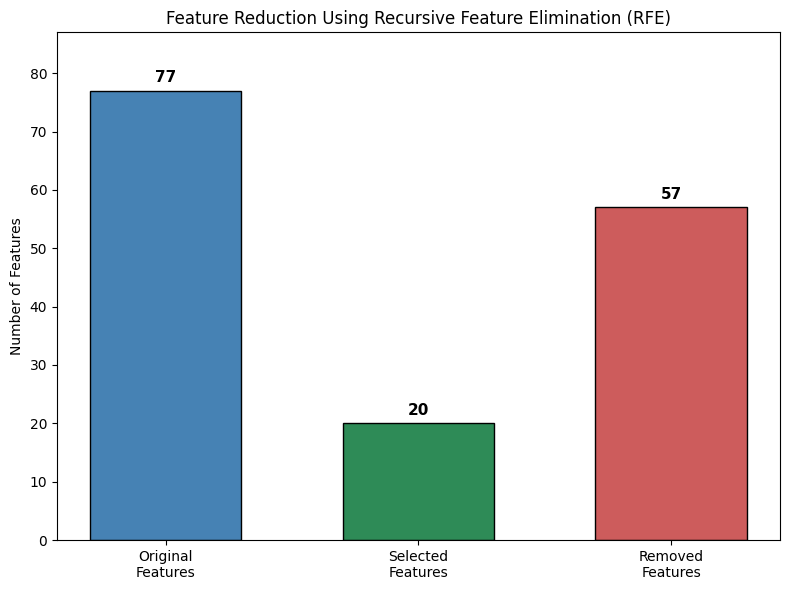

In [122]:
selected_features = X_train_res_scaled.columns[rfe.support_]



print("Selected Features:")
for feature in selected_features:
    print(feature)

print("\n===== SELECTED RFE FEATURES =====\n")

print("\nTotal Selected Features: \n", len(selected_features))


# =========================================
# RFE FEATURE REDUCTION VISUALIZATION
# =========================================

original_features = X_train_res_scaled.shape[1]
selected_features_count = len(selected_features)
removed_features = original_features - selected_features_count

plt.figure(figsize=(8,6))

categories = [
    "Original\nFeatures",
    "Selected\nFeatures",
    "Removed\nFeatures"
]

values = [
    original_features,
    selected_features_count,
    removed_features
]

# Blue, Green, Red
colors = ["steelblue", "seagreen", "indianred"]

bars = plt.bar(
    categories,
    values,
    color=colors,
    edgecolor="black",
    width=0.6
)

# Display values above bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 1,
        f"{int(height)}",
        ha='center',
        va='bottom',
        fontsize=11,
        fontweight='bold'
    )

plt.ylabel("Number of Features")
plt.title("Feature Reduction Using Recursive Feature Elimination (RFE)")

plt.ylim(0, original_features + 10)

plt.tight_layout()

plt.savefig(
    "rfe_feature_reduction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()







In [123]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train_rfe,y_train_res)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [124]:
rf_train_probs = rf.predict_proba(X_train_rfe)
rf_test_probs = rf.predict_proba(X_test_rfe)

In [125]:
X_train_meta = np.hstack((X_train_rfe, rf_train_probs))

X_test_meta = np.hstack((X_test_rfe, rf_test_probs))

In [126]:
from xgboost import XGBClassifier

In [127]:
xgb_model = XGBClassifier(random_state=42, eval_metric='logloss')

# Train model
xgb_model.fit(X_train_meta, y_train_res)

# Generate predictions
y_pred = xgb_model.predict(X_test_meta)


===== RFE_RF_XGBoost TEST PERFORMANCE =====
Accuracy:
0.999930094372597

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     25459
           1       1.00      1.00      1.00     31761

    accuracy                           1.00     57220
   macro avg       1.00      1.00      1.00     57220
weighted avg       1.00      1.00      1.00     57220


Confusion Matrix:
[[25457     2]
 [    2 31759]]


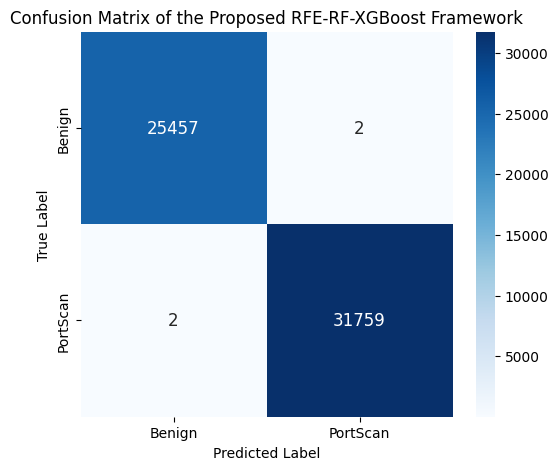


RFE AUC Score:
1.0


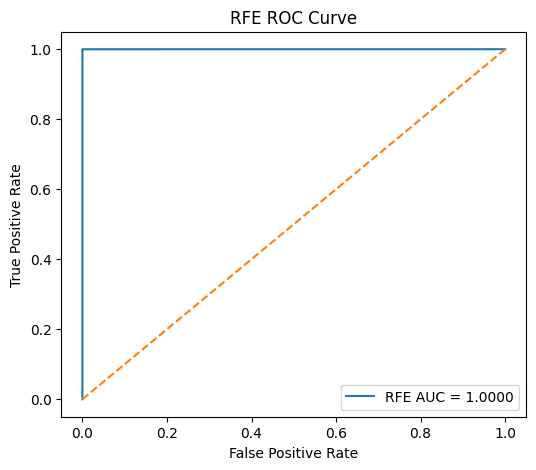

In [128]:
print("\n===== RFE_RF_XGBoost TEST PERFORMANCE =====")

print("Accuracy:")
print(accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# =========================================
# CONFUSION MATRIX VISUALIZATION
# RFE-RF-XGBOOST FRAMEWORK
# =========================================

import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot confusion matrix
plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Benign', 'PortScan'],
    yticklabels=['Benign', 'PortScan'],
    annot_kws={"size":12}
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.title(
    "Confusion Matrix of the Proposed RFE-RF-XGBoost Framework"
)

# Save high-resolution figure
plt.savefig(
    "confusion_matrix_rfe.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

y_probs_rfe = xgb_model.predict_proba(
    X_test_meta
)[:, 1]

fpr_rfe, tpr_rfe, thresholds_rfe = roc_curve(
    y_test,
    y_probs_rfe
)

auc_rfe = auc(
    fpr_rfe,
    tpr_rfe
)

print("\nRFE AUC Score:")
print(round(auc_rfe, 4))

# =========================================
# RFE ROC PLOT
# =========================================

plt.figure(figsize=(6,5))

plt.plot(
    fpr_rfe,
    tpr_rfe,
    label=f"RFE AUC = {auc_rfe:.4f}"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle='--'
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("RFE ROC Curve")

plt.legend()

plt.show()

In [129]:
y_train_pred = xgb_model.predict(X_train_meta)

print("\n===== RFE_RF_XGBoost TRAINING PERFORMANCE =====")

print("\nTraining Accuracy:")
print(accuracy_score(y_train_res, y_train_pred))

print("\nTraining Classification Report:")
print(classification_report(y_train_res, y_train_pred))

print("\nTraining Confusion Matrix:")
print(confusion_matrix(y_train_res, y_train_pred))

end_rfe_pipeline = time.time()

rfe_pipeline_time = (
    end_rfe_pipeline -
    start_rfe_pipeline
)

print("RFE Pipeline Time:")
print(rfe_pipeline_time, "seconds")


===== RFE_RF_XGBoost TRAINING PERFORMANCE =====

Training Accuracy:
0.9999842572987099

Training Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    127043
           1       1.00      1.00      1.00    127043

    accuracy                           1.00    254086
   macro avg       1.00      1.00      1.00    254086
weighted avg       1.00      1.00      1.00    254086


Training Confusion Matrix:
[[127043      0]
 [     4 127039]]
RFE Pipeline Time:
715.9742031097412 seconds


# Moth Flame Optimization

### Simplified MFO Feature Optimization

In [130]:
# =========================================
# START TIMER
# =========================================

start_mfo_pipeline = time.time()

# =========================================
# MFO PARAMETERS
# =========================================

population_size = 15
max_iterations = 10

num_features = X_train_res_scaled.shape[1]

In [131]:
# =========================================
# SPARSE MOTH INITIALIZATION
# =========================================

moths = np.zeros(
    (population_size, num_features),
    dtype=int
)

for i in range(population_size):

    subset_size = np.random.randint(5, 20)

    selected = np.random.choice(

        num_features,

        subset_size,

        replace=False

    )

    moths[i, selected] = 1

print("Initial Moth Population Created")

Initial Moth Population Created


In [132]:
# =========================================
# FITNESS FUNCTION
# =========================================

def fitness_function(solution):

    selected_indices = np.where(solution == 1)[0]

    # Prevent empty subset
    if len(selected_indices) == 0:
        return 1

    # =========================================
    # SELECT FEATURES
    # =========================================

    X_train_selected = X_train_res_scaled.iloc[
        :,
        selected_indices
    ]

    X_test_selected = X_test_scaled.iloc[
        :,
        selected_indices
    ]

    # =========================================
    # TEMP MODEL
    # =========================================

    temp_model = RandomForestClassifier(

        n_estimators=50,
        random_state=42,
        n_jobs=-1

    )

    temp_model.fit(
        X_train_selected,
        y_train_res
    )

    predictions = temp_model.predict(
        X_test_selected
    )

    # =========================================
    # CONFUSION MATRIX
    # =========================================

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions
    ).ravel()

    # =========================================
    # TPR & FPR
    # =========================================

    tpr = tp / (tp + fn + 1e-10)

    fpr = fp / (fp + tn + 1e-10)

    # =========================================
    # FEATURE RATIO
    # =========================================

    sf = len(selected_indices)

    nf = num_features

    feature_ratio = sf / nf

    # =========================================
    # FITNESS FUNCTION
    # LOWER IS BETTER
    # =========================================

    fitness = (

        0.10 * feature_ratio

        +

        0.45 * fpr

        +

        0.45 * (1 - tpr)

    )

    return fitness

In [133]:
# =========================================
# MFO MAIN LOOP
# =========================================

best_fitness_history = []

for iteration in range(max_iterations):

    print(f"\n========== ITERATION {iteration+1} ==========")

    # =========================================
    # EVALUATE MOTHS
    # =========================================

    fitness_scores = np.array([

        fitness_function(moth)

        for moth in moths

    ])

    # =========================================
    # SORT FLAMES
    # =========================================

    sorted_indices = np.argsort(
        fitness_scores
    )

    flames = moths[sorted_indices]

    flame_fitness = fitness_scores[
        sorted_indices
    ]

    best_fitness = flame_fitness[0]

    best_fitness_history.append(
        best_fitness
    )

    print(
        "Best Fitness:",
        best_fitness
    )

    # =========================================
    # UPDATE MOTH POSITIONS
    # =========================================

    b = 1

    for i in range(population_size):

        flame = flames[i]

        moth = moths[i]

        distance = np.abs(
            flame - moth
        )

        t = np.random.uniform(
            -1,
            1,
            num_features
        )

        updated_position = (

            distance

            *

            np.exp(b * t)

            *

            np.cos(2 * np.pi * t)

            +

            flame

        )

        # =========================================
        # SIGMOID TRANSFORMATION
        # =========================================

        sigmoid = (

            1 /

            (

                1 +

                np.exp(-updated_position)

            )

        )

        # =========================================
        # BINARY CONVERSION
        # =========================================

        binary_position = np.where(

            sigmoid > 0.5,
            1,
            0

        )

        moths[i] = binary_position

print("\nMFO Optimization Completed")


========== ITERATION 1 ==========
Best Fitness: 0.009788683693304887

========== ITERATION 2 ==========
Best Fitness: 0.012699460790735943

========== ITERATION 3 ==========
Best Fitness: 0.012699460790735943

========== ITERATION 4 ==========
Best Fitness: 0.012699460790735943

========== ITERATION 5 ==========
Best Fitness: 0.012699460790735943

========== ITERATION 6 ==========
Best Fitness: 0.012699460790735943

========== ITERATION 7 ==========
Best Fitness: 0.012699460790735943

========== ITERATION 8 ==========
Best Fitness: 0.012699460790735943

========== ITERATION 9 ==========
Best Fitness: 0.012699460790735943

========== ITERATION 10 ==========
Best Fitness: 0.012699460790735943

MFO Optimization Completed



===== SELECTED MFO FEATURES =====

Total Fwd Packets
Total Backward Packets
Bwd IAT Std
Bwd IAT Min
Bwd PSH Flags
URG Flag Count
Init_Win_bytes_forward
Init_Win_bytes_backward
min_seg_size_forward

Total Selected Features: 9


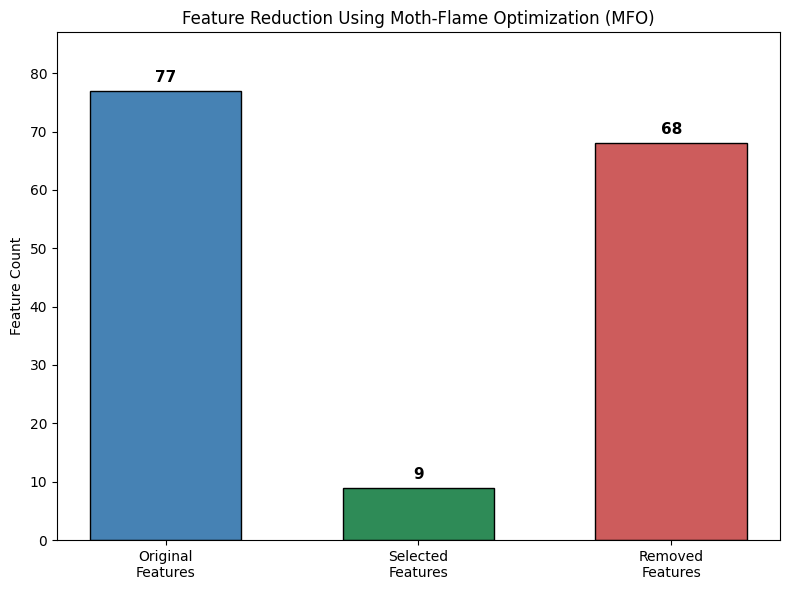

In [134]:
# =========================================
# BEST FEATURE SUBSET
# =========================================

best_solution = flames[0]

selected_indices = np.where(
    best_solution == 1
)[0]

top_features_mfo = (

    X_train_res_scaled.columns[
        selected_indices
    ].tolist()

)

# =========================================
# DISPLAY FEATURES
# =========================================

print("\n===== SELECTED MFO FEATURES =====\n")

for feature in top_features_mfo:

    print(feature)

print(
    "\nTotal Selected Features:",
    len(top_features_mfo)
)

# =========================================
# MFO FEATURE REDUCTION VISUALIZATION
# =========================================

original_features = X_train_res_scaled.shape[1]
selected_features_count = len(top_features_mfo)
removed_features = original_features - selected_features_count

plt.figure(figsize=(8,6))

categories = [
    "Original\nFeatures",
    "Selected\nFeatures",
    "Removed\nFeatures"
]

values = [
    original_features,
    selected_features_count,
    removed_features
]

# Blue, Green, Red
colors = ["steelblue", "seagreen", "indianred"]

bars = plt.bar(
    categories,
    values,
    color=colors,
    edgecolor="black",
    width=0.6
)

# Display only the values (no percentages)
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 1,
        f"{int(height)}",
        ha='center',
        va='bottom',
        fontsize=11,
        fontweight='bold'
    )

plt.ylabel("Feature Count")
plt.title("Feature Reduction Using Moth-Flame Optimization (MFO)")

plt.ylim(0, original_features + 10)

plt.tight_layout()

plt.savefig(
    "mfo_feature_reduction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [135]:
# =========================================
# FINAL FEATURE DATASETS
# =========================================

X_train_mfo = X_train_res_scaled[
    top_features_mfo
]

X_test_mfo = X_test_scaled[
    top_features_mfo
]

print("Final MFO datasets created")

Final MFO datasets created


In [136]:
# =========================================
# RANDOM FOREST MODEL
# =========================================

rf_mfo = RandomForestClassifier(

    n_estimators=100,
    random_state=42,
    n_jobs=-1

)

rf_mfo.fit(

    X_train_mfo,
    y_train_res

)

print("RF Training Completed")

RF Training Completed


In [137]:
# =========================================
# RF PROBABILITIES
# =========================================

rf_train_probs_mfo = rf_mfo.predict_proba(
    X_train_mfo
)

rf_test_probs_mfo = rf_mfo.predict_proba(
    X_test_mfo
)

# =========================================
# META DATASET
# =========================================

X_train_meta_mfo = np.hstack((

    X_train_mfo,
    rf_train_probs_mfo

))

X_test_meta_mfo = np.hstack((

    X_test_mfo,
    rf_test_probs_mfo

))

print("Meta dataset created")

Meta dataset created


In [138]:
# =========================================
# XGBOOST MODEL
# =========================================

xgb_mfo = XGBClassifier(

    random_state=42,
    eval_metric='logloss'

)

xgb_mfo.fit(

    X_train_meta_mfo,
    y_train_res

)

print("XGBoost Training Completed")

XGBoost Training Completed



===== MFO_RF_XGBoost TEST PERFORMANCE =====

Accuracy:
99.9021%

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     25459
           1       1.00      1.00      1.00     31761

    accuracy                           1.00     57220
   macro avg       1.00      1.00      1.00     57220
weighted avg       1.00      1.00      1.00     57220


Confusion Matrix:
[[25405    54]
 [    2 31759]]


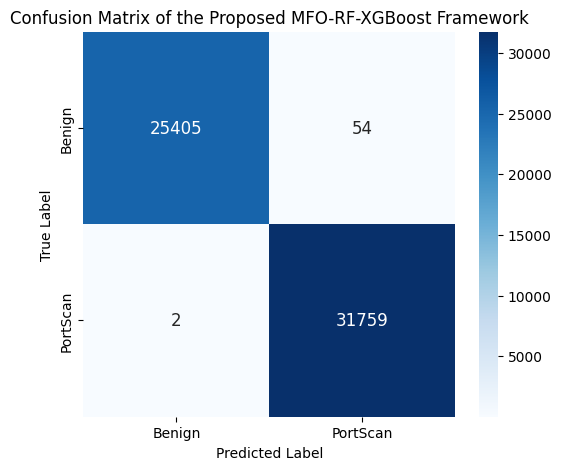


MFO AUC Score:
0.9999


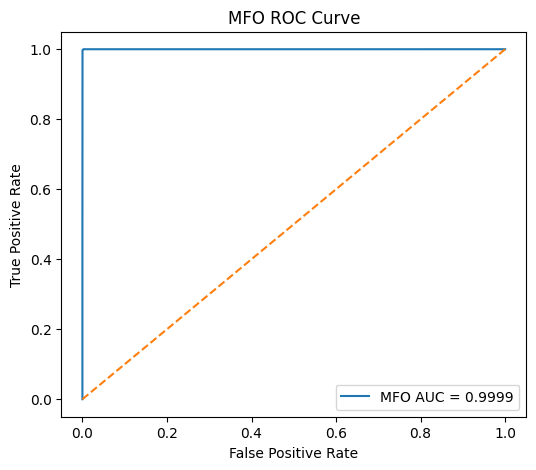

In [139]:
# =========================================
# TEST PREDICTIONS
# =========================================

y_pred_mfo = xgb_mfo.predict(
    X_test_meta_mfo
)

print("\n===== MFO_RF_XGBoost TEST PERFORMANCE =====")

# Accuracy
print("\nAccuracy:")

test_accuracy_mfo = accuracy_score(
        y_test,
        y_pred_mfo
    )

print(
    f"{test_accuracy_mfo * 100:.4f}%"
)

# Classification Report
print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred_mfo
    )
)

# Confusion Matrix
print("\nConfusion Matrix:")

print(
    confusion_matrix(
        y_test,
        y_pred_mfo
    )
)

# =========================================
# CONFUSION MATRIX VISUALIZATION
# MFO-RF-XGBOOST FRAMEWORK
# =========================================

cm_mfo = confusion_matrix(
    y_test,
    y_pred_mfo
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_mfo,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Benign', 'PortScan'],
    yticklabels=['Benign', 'PortScan'],
    annot_kws={"size":12}
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.title(
    "Confusion Matrix of the Proposed MFO-RF-XGBoost Framework"
)

plt.savefig(
    "confusion_matrix_mfo.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

y_probs_mfo = xgb_mfo.predict_proba(
    X_test_meta_mfo
)[:, 1]

fpr_mfo, tpr_mfo, thresholds_mfo = roc_curve(
    y_test,
    y_probs_mfo
)

auc_mfo = auc(
    fpr_mfo,
    tpr_mfo
)

print("\nMFO AUC Score:")

print(
    round(auc_mfo, 4)
)

plt.figure(figsize=(6,5))

plt.plot(
    fpr_mfo,
    tpr_mfo,
    label=f"MFO AUC = {auc_mfo:.4f}"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle='--'
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("MFO ROC Curve")

plt.legend()

plt.show()


In [140]:
# =========================================
# TRAIN PREDICTIONS
# =========================================

y_train_pred_mfo = xgb_mfo.predict(
    X_train_meta_mfo
)

# =========================================
# TRAIN PERFORMANCE
# =========================================

print("\n===== MFO_RF_XGBoost TRAIN PERFORMANCE =====")

# Accuracy
print("\nAccuracy:")

train_accuracy_mfo = accuracy_score(
        y_train_res,
        y_train_pred_mfo
    )


print(
    f"{train_accuracy_mfo * 100:.4f}%"
)

# Classification Report
print("\nClassification Report:")

print(
    classification_report(
        y_train_res,
        y_train_pred_mfo
    )
)

# Confusion Matrix
print("\nConfusion Matrix:")

print(
    confusion_matrix(
        y_train_res,
        y_train_pred_mfo
    )
)

# =========================================
# END TIMER
# =========================================

end_mfo_pipeline = time.time()

mfo_pipeline_time = (

    end_mfo_pipeline

    -

    start_mfo_pipeline

)

# =========================================
# DISPLAY PIPELINE TIME
# =========================================

print("\n===== MFO PIPELINE TIME =====")

print(

    "\nMFO Pipeline Time:",

    round(mfo_pipeline_time, 2),

    "seconds"

)


===== MFO_RF_XGBoost TRAIN PERFORMANCE =====

Accuracy:
99.8776%

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    127043
           1       1.00      1.00      1.00    127043

    accuracy                           1.00    254086
   macro avg       1.00      1.00      1.00    254086
weighted avg       1.00      1.00      1.00    254086


Confusion Matrix:
[[126733    310]
 [     1 127042]]

===== MFO PIPELINE TIME =====

MFO Pipeline Time: 259.17 seconds


In [141]:
import joblib
import pandas as pd
# =========================================
# CREATE METRICS DICTIONARY
# =========================================
metrics = {
    "rf_standalone_test_accuracy":
        accuracy_score(y_test, rf_standalone_pred) * 100,
    "rf_standalone_train_accuracy":
        accuracy_score(y_train_res, y_train_pred_rf_standalone) * 100,
    "rf_standalone_time":
        rf_standalone_time,
    "rf_standalone_auc":
        auc_rf,
    "xgb_standalone_test_accuracy":
        accuracy_score(y_test, xgb_standalone_pred) * 100,
    "xgb_standalone_train_accuracy":
        accuracy_score(y_train_res, y_train_pred_xgb_standalone) * 100,
    "xgb_standalone_time":
        xgb_standalone_time,
    "xgb_standalone_auc":
        auc_xgb,
    "rfe_test_accuracy":
        accuracy_score(y_test, y_pred) * 100,
    "rfe_train_accuracy":
        accuracy_score(y_train_res, y_train_pred) * 100,
    "rfe_pipeline_time":
        rfe_pipeline_time,
    "rfe_features":
        len(selected_features),
    "rfe_auc":
        auc_rfe,
    "mfo_test_accuracy":
        accuracy_score(y_test, y_pred_mfo) * 100,
    "mfo_train_accuracy":
        accuracy_score(y_train_res, y_train_pred_mfo) * 100,
    "mfo_pipeline_time":
        mfo_pipeline_time,
    "mfo_features":
        len(top_features_mfo),
    "mfo_auc":
        auc_mfo
}

# =========================================
# SAVE METRICS
# =========================================
joblib.dump(
    metrics,
    "comparison_metrics.pkl"
)
print("Metrics saved successfully")
# =========================================
# DISPLAY METRICS TABLE
# =========================================
comparison_results = pd.DataFrame({
    'Metric': [
        'Testing Accuracy',
        'Training Accuracy',
        'Number of Features',
        'Pipeline Time (seconds)',
        'AUC Score'
    ],
    'RF Standalone': [
        f"{metrics['rf_standalone_test_accuracy']:.4f}%",
        f"{metrics['rf_standalone_train_accuracy']:.4f}%",
        77,
        round(metrics['rf_standalone_time'], 2),
        round(metrics['rf_standalone_auc'], 4)
    ],
    'XGBoost Standalone': [
        f"{metrics['xgb_standalone_test_accuracy']:.4f}%",
        f"{metrics['xgb_standalone_train_accuracy']:.4f}%",
        77,
        round(metrics['xgb_standalone_time'], 2),
        round(metrics['xgb_standalone_auc'], 4)
    ],
    'RFE Pipeline': [
        f"{metrics['rfe_test_accuracy']:.4f}%",
        f"{metrics['rfe_train_accuracy']:.4f}%",
        metrics['rfe_features'],
        round(metrics['rfe_pipeline_time'], 2),
        round(metrics['rfe_auc'], 4)
    ],
    'MFO Pipeline': [
        f"{metrics['mfo_test_accuracy']:.4f}%",
        f"{metrics['mfo_train_accuracy']:.4f}%",
        metrics['mfo_features'],
        round(metrics['mfo_pipeline_time'], 2),
        round(metrics['mfo_auc'], 4)
    ]
})
comparison_results

Metrics saved successfully


,Metric,RF Standalone,XGBoost Standalone,RFE Pipeline,MFO Pipeline
0,Testing Accuracy,99.9913%,99.9965%,99.9930%,99.9021%
1,Training Accuracy,100.0000%,100.0000%,99.9984%,99.8776%
2,Number of Features,77,77,20,9
3,Pipeline Time (seconds),4.45,1.18,715.97,259.17
4,AUC Score,1.0,1.0,1.0,0.9999


In [142]:
import shap

explainer = shap.TreeExplainer(rf_mfo)

In [143]:
shap_values = explainer.shap_values(X_test_mfo)

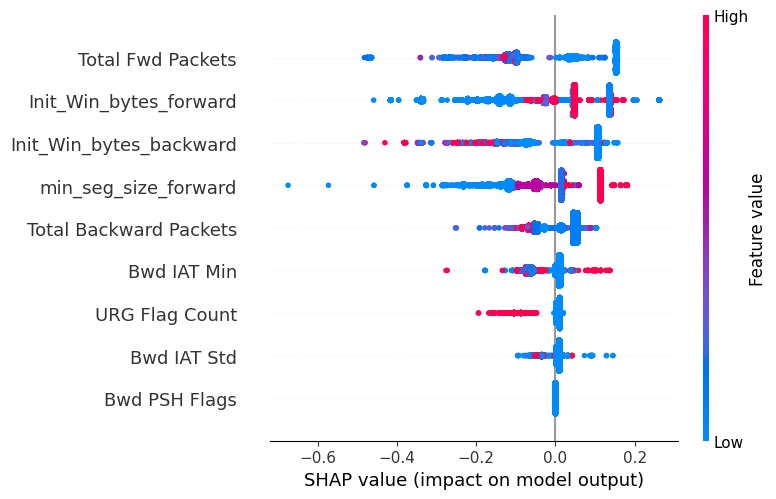

In [144]:
shap.summary_plot(
    shap_values[:, :, 1],
    X_test_mfo
)

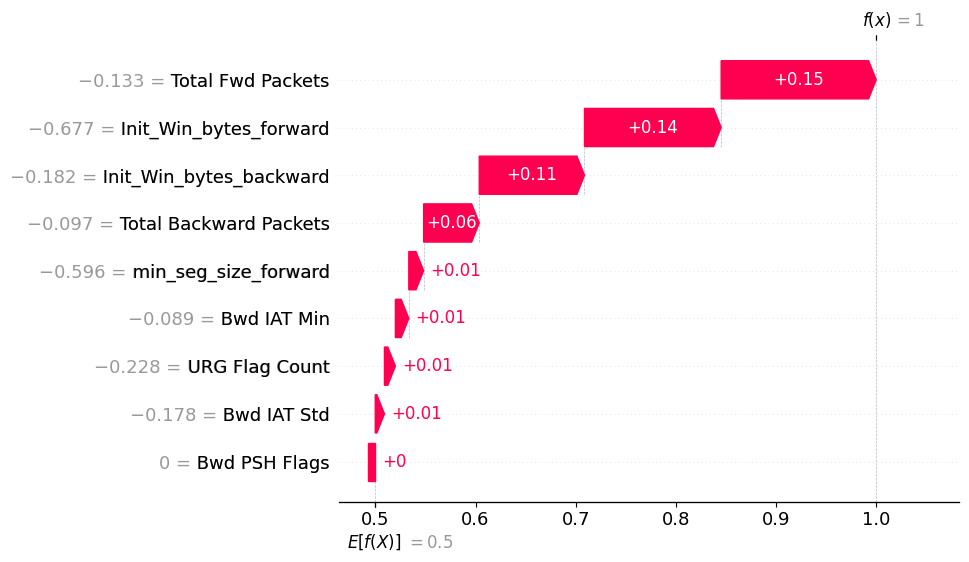

In [145]:
sample_index = 0

# Create SHAP explanation object
sample_explanation = shap.Explanation(
    values=shap_values[sample_index, :, 1],
    base_values=explainer.expected_value[1],
    data=X_test_mfo.iloc[sample_index],
    feature_names=X_test_mfo.columns
)

# Waterfall plot
shap.plots.waterfall(sample_explanation)

In [146]:
import joblib

# =========================================
# SAVE RFE PIPELINE
# =========================================

joblib.dump(rf, 'rf_rfe.pkl')

joblib.dump(xgb_model, 'xgb_rfe.pkl')

joblib.dump(selected_features, 'rfe_features.pkl')


# =========================================
# SAVE MFO PIPELINE
# =========================================

joblib.dump(rf_mfo, 'rf_mfo.pkl')

joblib.dump(xgb_mfo, 'xgb_mfo.pkl')

joblib.dump(top_features_mfo, 'mfo_features.pkl')


# =========================================
# SAVE SHARED PREPROCESSOR
# =========================================

joblib.dump(scaler, 'scaler.pkl')

print("All models saved successfully.")

All models saved successfully.
